# Iteration Zero — Baseline Model & Data Exploration
**Project:** Automated Vehicle Damage Classification for Motor Insurance Claims  
**Dataset:** CarDD (Car Damage Detection) — 4,000 images, 6 classes: Dent, Scratch, Crack, Glass Shatter, Lamp Broken, Tire Flat

**Goal of this notebook:** confirm that the data contains a learnable signal, using a deliberately simple k-Nearest Neighbors (k-NN) baseline — no tuning, no feature engineering, no CNN yet. That comes later, in Iteration 2.

**Before running:** download CarDD and update the `CARDD_ROOT` path in the config cell below. See the markdown cell right after this one for exact download steps.

## Step 0 — Download the dataset (do this once, outside the notebook)

**Recommended: Kaggle mirror (instant, no waiting)**
1. Create a free Kaggle account if you don't have one: https://www.kaggle.com
2. Go to https://www.kaggle.com/datasets/issamjebnouni/cardd
3. Click **Download** and unzip it somewhere on your computer.

**Also submit the official licensing form in parallel** (not urgent, but do it soon): https://cardd-ustc.github.io/docs/CarDD_license.pdf — this gets you the authors' own copy and lets you cite the dataset properly.

**Note on folder structure:** the Kaggle mirror's actual layout is flatter than CarDD's official paper describes — it looks like this:
```
archive (1)/
  train/          <- images
  val/            <- images
  test/           <- images
  train.json      <- annotations for train/
  val.json        <- annotations for val/
  test.json       <- annotations for test/
  image_info.xlsx
```
The config cell below (Step 2) is already set up to detect this layout automatically, as well as the original paper's layout, in case yours looks different.

## Step 1 — Install and import required libraries

In [1]:
# Run this once. If you already have these installed, this will just confirm it.
# !pip install pycocotools scikit-learn matplotlib pillow numpy pandas

import json as _json
import glob
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

from pycocotools.coco import COCO

## Step 2 — Configuration (update this path)

In [2]:
import glob, os

# CHANGE THIS to the folder that directly contains train.json, val.json, test.json
# and the train/, val/, test/ image folders. Use an absolute path to be safe, e.g.:
#   CARDD_ROOT = r"C:\Users\you\Documents\Semester 4 ProfTask\Personal\archive (1)"
CARDD_ROOT =  r"C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)"



# Auto-detect annotation JSON files. Handles two possible layouts:
#   A) CARDD_ROOT/annotations/instances_train2017.json  (layout described in the CarDD paper)
#   B) CARDD_ROOT/train.json                              (actual Kaggle mirror layout - this is likely yours)
candidates = sorted(glob.glob(os.path.join(CARDD_ROOT, "annotations", "instances_*.json")))
if not candidates:
    candidates = sorted(glob.glob(os.path.join(CARDD_ROOT, "*.json")))

print("Found annotation files:")
for f in candidates:
    print(" -", f)

ann_files = candidates
assert len(ann_files) > 0, (
    "No annotation files found. Double-check CARDD_ROOT points to the folder that contains "
    "train.json / val.json / test.json (or an annotations/ subfolder)."
)

Found annotation files:
 - C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\test.json
 - C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\train.json
 - C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\val.json


## Step 3 — Load annotations and build one combined pool

We load all available splits (train/val/test) and combine them into one pool of labeled images. We'll create our own train/test split later — for this quick Iteration Zero check, we don't need to respect the original split boundaries.

In [3]:
import time

all_images = {}   # (split, image_id) -> {file_name, full_path, split}
all_anns = []      # list of dicts: split, image_id, category_id, area
cat_id_to_name = {}

from pathlib import Path

def build_filename_index(root_dir):
    """Walk root_dir recursively and map every image filename found to its full path.
    Prints progress every 500 files so long searches don't look frozen.
    If two files share the same name in different subfolders, the last one found wins."""
    index = {}
    exts = (".jpg", ".jpeg", ".png", ".bmp")
    scanned = 0
    start = time.time()
    for dirpath, _, filenames in os.walk(root_dir):
        for fname in filenames:
            scanned += 1
            if scanned % 2000 == 0:
                elapsed = time.time() - start
                print(f"    ...scanned {scanned} files so far ({elapsed:.1f}s elapsed, still going)")
            if fname.lower().endswith(exts):
                if fname in index:
                    print(f"  [warning] duplicate filename '{fname}' found — using the most recent match")
                index[fname] = os.path.join(dirpath, fname)
    print(f"    scan finished: {scanned} total files checked in {time.time()-start:.1f}s")
    return index

for ann_file in ann_files:
    # Works for both 'instances_train2017.json' -> 'train2017' and 'train.json' -> 'train'
    split_name = Path(ann_file).stem.replace("instances_", "")

    # Try a few likely top-level folder names for this split, then search inside recursively
    candidate_dirs = [
        os.path.join(CARDD_ROOT, split_name),
        os.path.join(CARDD_ROOT, split_name.replace("2017", "")),
        os.path.join(CARDD_ROOT, split_name + "2017"),
    ]
    img_dir = next((d for d in candidate_dirs if os.path.isdir(d)), None)
    if img_dir is None:
        raise FileNotFoundError(
            "Could not find an image folder for split '" + split_name + "'. "
            "Tried: " + str(candidate_dirs) + ". "
            "Check your folder names and adjust candidate_dirs above if needed."
        )

    print(f"Indexing images under {img_dir} ...")
    filename_index = build_filename_index(img_dir)
    print(f"  found {len(filename_index)} image files")

    coco = COCO(ann_file)

    cat_id_to_name.update({c["id"]: c["name"] for c in coco.loadCats(coco.getCatIds())})

    missing = 0
    for img_id, img_info in coco.imgs.items():
        fname = img_info["file_name"]
        base_fname = os.path.basename(fname)
        full_path = filename_index.get(base_fname)
        if full_path is None:
            missing += 1
            continue
        all_images[(split_name, img_id)] = {
            "file_name": fname,
            "full_path": full_path,
            "split": split_name,
        }

    if missing:
        print(f"  [warning] {missing} images listed in {ann_file} were not found on disk and will be skipped")

    for ann in coco.anns.values():
        if (split_name, ann["image_id"]) not in all_images:
            continue
        all_anns.append({
            "split": split_name,
            "image_id": ann["image_id"],
            "category_id": ann["category_id"],
            "area": ann.get("area", 0),
            "bbox": ann.get("bbox", None),  # [x, y, width, height] in COCO format — needed to crop this damage region
        })

print(f"Total images found: {len(all_images)}")
print(f"Total annotated instances found: {len(all_anns)}")
print(f"Categories: {cat_id_to_name}")

Indexing images under C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\test ...
    scan finished: 374 total files checked in 0.0s
  found 374 image files
loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
Indexing images under C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\train ...
    ...scanned 2000 files so far (0.0s elapsed, still going)
    scan finished: 2816 total files checked in 0.0s
  found 2816 image files
loading annotations into memory...
Done (t=0.33s)
creating index...
index created!
Indexing images under C:\Users\user\Documents\Semester 4 ProfTask\Personal\archive (1)\val ...
    scan finished: 810 total files checked in 0.0s
  found 810 image files
loading annotations into memory...
Done (t=0.10s)
creating index...
index created!
Total images found: 4000
Total annotated instances found: 8740
Categories: {1: 'dent', 2: 'scratch', 3: 'crack', 4: 'glass shatter', 5: 'lamp broken', 6: 'tire flat'}


## Step 4 — Exploratory Data Analysis (EDA)

Before touching the model, let's actually look at the data — this fills in Section 2 of your Iteration Zero document.

Instances per category:
category_name
scratch          3595
dent             2543
crack             898
lamp broken       704
glass shatter     681
tire flat         319
Name: count, dtype: int64


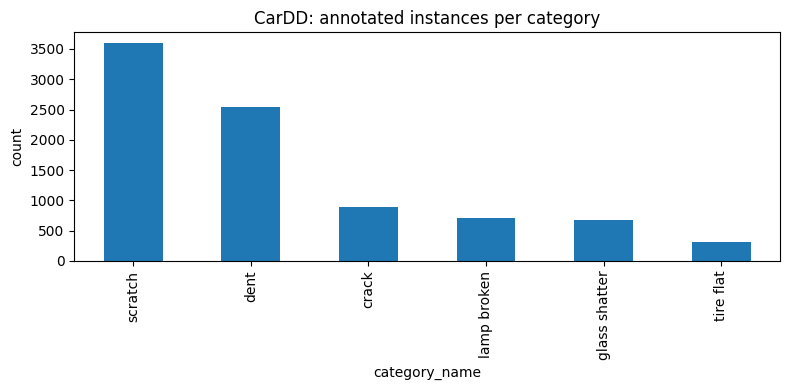

In [4]:
anns_df = pd.DataFrame(all_anns)
anns_df["category_name"] = anns_df["category_id"].map(cat_id_to_name)

# How many annotated instances per category overall?
instance_counts = anns_df["category_name"].value_counts()
print("Instances per category:")
print(instance_counts)

instance_counts.plot(kind="bar", figsize=(8,4), title="CarDD: annotated instances per category")
plt.ylabel("count")
plt.tight_layout()
plt.show()

In [5]:
# How many images have more than one damage instance? This matters for our dominant-label step.
images_per_ann_count = anns_df.groupby(["split", "image_id"]).size()
print(f"Images with exactly 1 annotated instance: {(images_per_ann_count == 1).sum()}")
print(f"Images with more than 1 annotated instance: {(images_per_ann_count > 1).sum()}")

Images with exactly 1 annotated instance: 1816
Images with more than 1 annotated instance: 2184


## Step 5 — Extract each bounding box as its own labeled crop

**Updated based on supervisor feedback.** The previous version of this step collapsed each image down to a single "dominant" label (the largest damage area), discarding information whenever an image had more than one type of damage. Instead, every individually annotated bounding box is now treated as its own training example, with its own single label — this also means that when we crop to just that box in Step 6, the model sees a zoomed-in view of the actual damage instead of a small patch lost inside a shrunk full-car photo.

In [6]:
# One row per individual annotated damage instance (not one row per image).
# Each row keeps its own bbox, so Step 6 can crop exactly that region out of the original photo.
crops_df = anns_df.copy()
crops_df["full_path"] = crops_df.apply(
    lambda r: all_images[(r["split"], r["image_id"])]["full_path"], axis=1)

print(f"Total individual damage crops to use: {len(crops_df)}")
print("Class balance (now at the instance level, not the image level):")
print(crops_df["category_name"].value_counts())

Total individual damage crops to use: 8740
Class balance (now at the instance level, not the image level):
category_name
scratch          3595
dent             2543
crack             898
lamp broken       704
glass shatter     681
tire flat         319
Name: count, dtype: int64


## Step 6 — Crop to the bounding box, then extract features

**Updated based on supervisor feedback.** Previously, the *entire photo* was resized to 32x32, so if the damage only covered a small part of the image, most of what the model saw after shrinking was irrelevant background. Now, each image is first cropped down to just its annotated bounding box — so the model only ever sees the actual damage region — and that crop is resized to 32x32, the same size as before, so results are still fairly comparable to the earlier run.

In [20]:
import time

IMG_SIZE = (64, 64)  # change this one line to try another size, e.g. (32, 32) or (96, 96)

# Resized crops are saved here, in one folder per size and per category
SAVE_DIR = os.path.join("resized_crops", f"{IMG_SIZE[0]}x{IMG_SIZE[1]}")

def crop_to_bbox(img, bbox):
    """COCO bbox format is [x, y, width, height]. Clips to the image bounds in case
    annotation coordinates run slightly outside the actual image."""
    x, y, w, h = bbox
    left, top = max(0, x), max(0, y)
    right, bottom = min(img.width, x + w), min(img.height, y + h)  # keeps the crop inside the image
    return img.crop((left, top, right, bottom))

def load_crop_and_flatten(path, bbox, save_path, size=IMG_SIZE):
    if os.path.exists(save_path):
        # Already made in an earlier run: just load the saved crop
        resized = Image.open(save_path).convert("RGB")
    else:
        # Open the photo, cut out only the damaged area, resize it, and save it
        img = Image.open(path).convert("RGB")
        resized = crop_to_bbox(img, bbox).resize(size)
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        resized.save(save_path)
    return np.asarray(resized, dtype=np.float32).flatten() / 255.0

features = []
labels = []
skipped = 0

total = len(crops_df)
start = time.time()
print(f"Processing {total} crops at {IMG_SIZE[0]}x{IMG_SIZE[1]}... (progress printed every 1000)")

# One row per damage: a photo with a dent and a scratch gives two examples, each with its own label
for i, (idx, row) in enumerate(crops_df.iterrows(), start=1):
    try:
        if row["bbox"] is None:
            raise ValueError("missing bbox")
        save_path = os.path.join(SAVE_DIR, row["category_name"], f"{idx}.png")
        features.append(load_crop_and_flatten(row["full_path"], row["bbox"], save_path))
        labels.append(row["category_name"])
    except (FileNotFoundError, OSError, ValueError):
        skipped += 1
    if i % 1000 == 0 or i == total:
        elapsed = time.time() - start
        print(f"  ...{i}/{total} crops processed ({elapsed:.1f}s elapsed, {skipped} skipped so far)")

X = np.stack(features)
y = np.array(labels)
print(f"Done in {time.time()-start:.1f}s")
print(f"Feature matrix shape: {X.shape}")
print(f"Skipped (missing/unreadable) crops: {skipped}")
print(f"Resized crops saved in: {os.path.abspath(SAVE_DIR)}")

Processing 8740 crops at 64x64... (progress printed every 1000)
  ...1000/8740 crops processed (15.0s elapsed, 0 skipped so far)
  ...2000/8740 crops processed (30.3s elapsed, 0 skipped so far)
  ...3000/8740 crops processed (46.5s elapsed, 0 skipped so far)
  ...4000/8740 crops processed (62.3s elapsed, 0 skipped so far)
  ...5000/8740 crops processed (77.1s elapsed, 0 skipped so far)
  ...6000/8740 crops processed (91.8s elapsed, 0 skipped so far)
  ...7000/8740 crops processed (106.2s elapsed, 0 skipped so far)
  ...8000/8740 crops processed (120.9s elapsed, 0 skipped so far)
  ...8740/8740 crops processed (131.8s elapsed, 0 skipped so far)
Done in 132.2s
Feature matrix shape: (8740, 12288)
Skipped (missing/unreadable) crops: 0
Resized crops saved in: C:\Users\user\Documents\Semester 4 ProfTask\Personal\resized_crops\64x64


## Step 7 — Train / test split

In [24]:
# Balanced test set: the same number of crops from every category,
# so no single class (scratch, dent) dominates the score.
rng = np.random.default_rng(42)
classes, counts = np.unique(y, return_counts=True)

# 20% of the smallest class (tire flat, 319 crops) -> 63 crops per category
n_test_per_class = int(counts.min() * 0.2)

test_idx = np.concatenate([
    rng.choice(np.where(y == c)[0], size=n_test_per_class, replace=False)
    for c in classes
])
train_mask = np.ones(len(y), dtype=bool)
train_mask[test_idx] = False

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_idx], y[test_idx]

print(f"Train size: {len(X_train)}, Test size: {len(X_test)}")
print("Test crops per category:")
print(pd.Series(y_test).value_counts())

Train size: 8362, Test size: 378
Test crops per category:
crack            63
dent             63
glass shatter    63
lamp broken      63
scratch          63
tire flat        63
Name: count, dtype: int64


## Step 8 — Train the k-NN baseline (no tuning, default parameters)

In [25]:
#Baseline for comparison: what would pure random guessing score?
n_classes = len(set(y))
random_baseline = 1 / n_classes
print(f"Number of classes: {n_classes}")
print(f"Random-guess baseline: {random_baseline:.1%}")

Number of classes: 6
Random-guess baseline: 16.7%


In [26]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"k-NN baseline accuracy: {acc:.3f}")

k-NN baseline accuracy: 0.254


## Step 9 — Evaluate

Remember: the bar to clear here isn't high accuracy — it's beating random guessing. With 6 classes, random guessing scores roughly **16.7%**. Anything meaningfully above that means the data has a learnable signal worth pursuing with a more capable model (CNN) in later iterations.

               precision    recall  f1-score   support

        crack       0.57      0.19      0.28        64
         dent       0.26      0.48      0.34        64
glass shatter       0.75      0.05      0.09        64
  lamp broken       1.00      0.03      0.06        64
      scratch       0.21      0.72      0.32        64
    tire flat       1.00      0.28      0.44        64

     accuracy                           0.29       384
    macro avg       0.63      0.29      0.26       384
 weighted avg       0.63      0.29      0.26       384



<function matplotlib.pyplot.show(close=None, block=None)>

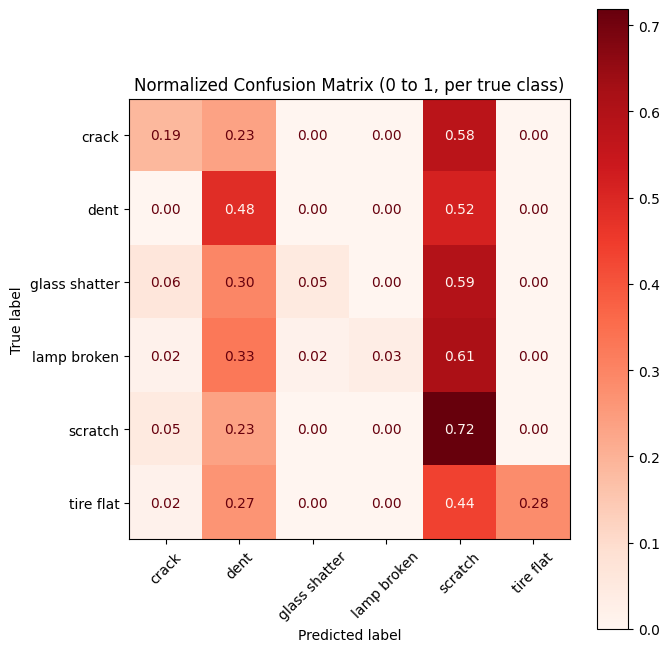

In [11]:
print(classification_report(y_test, y_pred))

# Row-normalized (0 to 1) — each row sums to 1, showing what % of each TRUE class
# was predicted as each label. Fairer than raw counts given class imbalance.
cm_norm = confusion_matrix(y_test, y_pred, labels=knn.classes_, normalize="true")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=knn.classes_)
fig, ax = plt.subplots(figsize=(7, 7))
disp.plot(ax=ax, xticks_rotation=45, cmap="Reds", values_format=".2f")
plt.title("Normalized Confusion Matrix (0 to 1, per true class)")
plt.tight_layout()
plt.show #balance out the proportions for cateogries in the test dataset

## Step 10 — Conclusion

**Previous run (whole-image resize + dominant label):** 39.4% accuracy, vs. 16.7% random-guess baseline. Crack and lamp broken were almost never correctly recognized; the model defaulted heavily toward "scratch" (the largest class).

**This run (cropped bounding boxes, one label per crop):** 45.7% accuracy on 1,748 test crops.

- **k-NN accuracy on cropped data:** 45.7%, compared with a random-guess baseline of 16.7%. The random baseline did not change, because it only depends on the number of classes (6), not on how many examples each class has. A stricter baseline is to always predict the largest class ("scratch"): that would already score 41.1% (719 of 1,748 test crops). So the model beats random guessing clearly, but always-guess-scratch only slightly.
- **Did accuracy improve compared to the 39.4% baseline?** Yes, by 6.3 percentage points (39.4% → 45.7%). Cropping to the damage gives the model a clearer view of what it needs to recognize, and each damage now has its own correct label. However, the comparison with always-guess-scratch (41.1%) shows the gain is still modest.
- **Which classes does the model confuse most now?** Crack (recall 0.13), glass shatter (0.07) and lamp broken (0.04) are still almost never recognized. The model predicts "scratch" for about 1,130 of the 1,748 test crops (65%) and "dent" for about 520 (30%), so most cracks, shattered glass and broken lamps end up classified as scratch or dent. Dent and scratch are also confused with each other: only 42% of dents are recognized, and less than half of all "scratch" predictions are actually scratches (precision 0.47). Tire flat does better (recall 0.30) and, like lamp broken and glass shatter, is almost never predicted wrongly when the model does choose it (precision 0.69–1.00).
- **Does cropping appear to have fixed the issues Bas identified?** Partly. Cropping fixed the data problems: small damages are no longer reduced to a few pixels, and photos with multiple damages no longer lose information to a single dominant label. Accuracy improved as a result. But the main symptom is still there: the model still defaults heavily to "scratch" and still rarely recognizes crack and lamp broken. This suggests the remaining problem is the model itself (k-NN on raw pixels compares colours pixel by pixel and cannot recognize shapes) combined with the class imbalance. The next iteration should use a CNN and a way to handle the imbalance.



In [12]:
look into suport vector machine 
no need to 32x32 look into that 

SyntaxError: invalid decimal literal (2083160337.py, line 2)